# 3장. Paderborn 데이터 이해하기

In [1]:
# [준비 셀] 모든 노트북의 첫 코드 셀입니다. 항상 먼저 실행하세요.
from pathlib import Path
import sys

ROOT = Path.cwd().resolve().parents[1]          # docs/manual → 프로젝트 루트
assert (ROOT / "src/bearing_kd").exists(), "docs/manual 폴더에서 노트북을 열어야 합니다"
CODE = ROOT / "docs/manual/code"                 # 챕터별 완성 스크립트 위치
sys.path.insert(0, str(CODE))                    # 스크립트의 함수를 import 해서 쓰기 위해
print("프로젝트 루트 확인 완료:", ROOT.name)

프로젝트 루트 확인 완료: vib-onnx


모델을 만들기 전에 **데이터가 어떻게 생겼는지** 직접 열어 봅니다. ML에서 가장 흔한 실수는 데이터를 제대로 보지 않고 모델부터 만드는 것입니다.

## 3.1 데이터 출처

독일 Paderborn 대학 KAt(Chair of Design and Drive Technology)이 공개한 베어링 데이터입니다. 전기 모터에 베어링을 끼워 돌리면서 진동, 모터 전류, 속도, 토크, 온도를 기록했습니다.

- 공식 페이지: https://mb.uni-paderborn.de/kat/forschung/bearing-datacenter
- 라이선스: **CC BY-NC 4.0** (출처 표기, 비상업적 이용)
- 인용: C. Lessmeier 외, *PHM Society European Conference*, 2016

## 3.2 베어링 코드와 라벨

베어링마다 `K001`, `KA04` 같은 코드가 있고, 코드가 곧 정답(라벨)입니다.

| 코드 | 의미 | 라벨 |
|---|---|---|
| `K001`–`K006` (K + 숫자 3자리) | 정상 베어링 | **0 (정상)** |
| `KA01`, `KA04` … | 외륜(Outer race) 손상 | **1 (고장)** |
| `KI01`, `KI03` … | 내륜(Inner race) 손상 | **1 (고장)** |
| `KB23`, `KB24`, `KB27` | 외륜 + 내륜 복합 손상 | **1 (고장)** |

이 프로젝트는 손상 위치를 구분하지 않고 **정상 vs 고장** 두 가지로만 분류합니다.

In [2]:
import ch03_inspect_data as ch03

for code in ["K001", "K004", "KA04", "KI03", "KB24"]:
    print(code, "→ 라벨", ch03.bearing_label(code))

try:
    ch03.bearing_label("X123")
except ValueError as e:
    print("잘못된 코드는 에러:", e)

K001 → 라벨 0
K004 → 라벨 0
KA04 → 라벨 1
KI03 → 라벨 1
KB24 → 라벨 1
잘못된 코드는 에러: 알 수 없는 베어링 코드: X123


## 3.3 파일 이름 = 운전 조건 + 베어링 + 번호

베어링 하나에는 `.mat` 파일이 **80개** 있습니다. 운전 조건 4가지 × 조건마다 20번 측정입니다.

`N15_M07_F10_K001_1.mat` 읽는 법:

| 부분 | 의미 |
|---|---|
| `N15` | 회전 속도 1500 rpm (`N09` = 900 rpm) |
| `M07` | 부하 토크 0.7 Nm (`M01` = 0.1 Nm) |
| `F10` | 반경 방향 힘 1000 N (`F04` = 400 N) |
| `K001` | 베어링 코드 |
| `1` | 같은 조건에서 몇 번째 측정인지 (1–20) |

In [3]:
RAW = ROOT / "data/raw/paderborn"
bearings = sorted(p.name for p in RAW.iterdir() if p.is_dir() and any(p.glob("*.mat")))
print("압축이 풀린 베어링:", bearings)

from collections import Counter
files = sorted((RAW / "K001").glob("*.mat"))
print("\nK001 파일 수:", len(files))
print("운전 조건별:", dict(Counter(f.name[:11] for f in files)))
for cond, desc in ch03.CONDITIONS.items():
    print(f"  {cond}: {desc}")

압축이 풀린 베어링: ['K001', 'K002', 'K003', 'K004', 'K005', 'K006', 'KA03', 'KA04', 'KA05', 'KA06', 'KB24', 'KB27', 'KI03']

K001 파일 수: 80
운전 조건별: {'N09_M07_F10': 20, 'N15_M01_F10': 20, 'N15_M07_F04': 20, 'N15_M07_F10': 20}
  N15_M07_F10: 1500 rpm, 부하 토크 0.7 Nm, 반경 방향 힘 1000 N (기준 조건)
  N09_M07_F10: 900 rpm, 0.7 Nm, 1000 N (저속)
  N15_M01_F10: 1500 rpm, 0.1 Nm, 1000 N (저부하)
  N15_M07_F04: 1500 rpm, 0.7 Nm, 400 N (약한 반경 방향 힘)


## 3.4 압축 풀기

공식 사이트에서 베어링마다 `.rar` 파일(약 170 MB)을 받습니다. 풀면 베어링 하나에 약 670 MB입니다. macOS에는 `.rar`를 풀 수 있는 `bsdtar`가 기본으로 있습니다.

```bash
cd data/raw/paderborn
bsdtar -xf K001.rar        # → K001/ 폴더에 .mat 80개 + PDF 2개
```

> 필요한 베어링만 푸세요. 전부 풀면 20 GB가 넘습니다. 이 매뉴얼은 K001, K002, K003, K004, KA03, KA04, KI03, KB24, KB27을 씁니다.

## 3.5 `.mat` 파일 열기

`.mat`은 MATLAB 데이터 형식입니다. 파이썬에서는 `scipy.io.loadmat`으로 엽니다. 안에는 파일 이름과 같은 이름의 **구조체** 하나가 있고, 그 안의 `Y`에 측정 채널들이 들어 있습니다.

In [4]:
from scipy.io import loadmat

path = RAW / "K001/N15_M07_F10_K001_1.mat"
mat = loadmat(path, squeeze_me=True, struct_as_record=False)
print("최상위 키:", [k for k in mat if not k.startswith("__")])

record = mat[path.stem]
print("구조체 필드:", record._fieldnames)

최상위 키: ['N15_M07_F10_K001_1']
구조체 필드: ['Info', 'X', 'Y', 'Description']


In [5]:
print(f"{'채널':22s} {'샘플 수':>9s}  기록 방식")
for name, length, raster in ch03.list_channels(record):
    print(f"{name:22s} {length:>9,}  {raster}")

채널                          샘플 수  기록 방식
force                     16,001  Mech_4kHz
phase_current_1          256,001  HostService
phase_current_2          256,001  HostService
speed                     16,001  Mech_4kHz
temp_2_bearing_module          5  Temp_1Hz
torque                    16,001  Mech_4kHz
vibration_1              256,001  HostService


여러 채널 중 우리가 쓰는 것은 **`vibration_1`** (진동 가속도, 1축) 하나입니다.

- 샘플 256,001개. 이 채널은 **1초에 64,000번**(64 kHz) 기록했으므로 256,001 ÷ 64,000 ≈ **4초** 분량입니다.
- `force`, `speed`, `torque`는 4 kHz, 온도는 1 Hz로 훨씬 드물게 기록했습니다.

In [6]:
import numpy as np

x_normal = ch03.extract_vibration(RAW / "K001/N15_M07_F10_K001_1.mat")
x_fault = ch03.extract_vibration(RAW / "KA04/N15_M07_F10_KA04_1.mat")
for name, x in [("K001 정상", x_normal), ("KA04 고장", x_fault)]:
    print(f"{name}: {x.size:,} 샘플 = {x.size / ch03.RAW_FS:.2f}초, dtype {x.dtype}, "
          f"평균 {x.mean():+.4f}, 표준편차 {x.std():.4f}, 최소 {x.min():.3f}, 최대 {x.max():.3f}")

K001 정상: 256,001 샘플 = 4.00초, dtype float32, 평균 -0.0188, 표준편차 0.4062, 최소 -4.929, 최대 4.391
KA04 고장: 256,004 샘플 = 4.00초, dtype float32, 평균 +0.0430, 표준편차 0.4753, 최소 -3.220, 최대 2.368


## 3.6 눈으로 보기

앞부분 0.02초(1,280샘플)를 그려 봅니다.

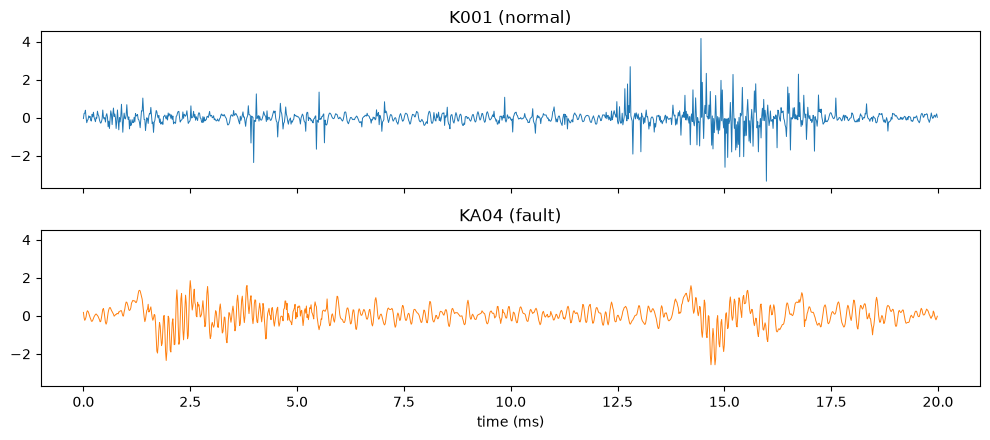

In [7]:
import matplotlib.pyplot as plt

fs = ch03.RAW_FS
n = int(0.02 * fs)
t = np.arange(n) / fs * 1000
fig, axes = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True, sharey=True)
axes[0].plot(t, x_normal[:n], lw=0.7); axes[0].set_title("K001 (normal)")
axes[1].plot(t, x_fault[:n], lw=0.7, color="C1"); axes[1].set_title("KA04 (fault)")
axes[1].set_xlabel("time (ms)")
plt.tight_layout(); plt.show()

사람 눈으로는 정상과 고장을 구분하기 어렵습니다. 고장 베어링에서는 볼이 손상 부위를 지날 때마다 작은 **충격**이 생기는데, 모터와 장비의 다른 진동에 섞여 잘 보이지 않습니다. 이 차이를 찾아내는 일을 모델에게 맡깁니다.

4초 전체를 보면 신호가 대체로 일정한 크기로 계속 흔들립니다.

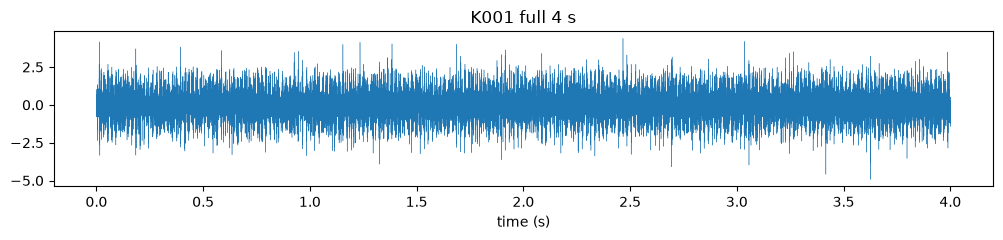

In [8]:
fig, ax = plt.subplots(figsize=(10, 2.5))
ax.plot(np.arange(x_normal.size) / fs, x_normal, lw=0.3)
ax.set_xlabel("time (s)"); ax.set_title("K001 full 4 s")
plt.tight_layout(); plt.show()

## 3.7 정리

- 입력: `vibration_1` 한 채널, 64 kHz, 파일당 약 4초
- 정답: 폴더 이름(베어링 코드)에서 결정 (K+3자리 = 0, KA/KI/KB = 1)
- 베어링당 80개 파일 = 운전 조건 4가지 × 20회

## 3장 완성 코드: `code/ch03_inspect_data.py`
```bash
python docs/manual/code/ch03_inspect_data.py --normal K001 --fault KA04
```

In [9]:
%run code/ch03_inspect_data.py

파일: data/raw/paderborn/K001/N15_M07_F10_K001_1.mat
운전 조건 N15_M07_F10: 1500 rpm, 부하 토크 0.7 Nm, 반경 방향 힘 1000 N (기준 조건)

구조체 필드: ['Info', 'X', 'Y', 'Description']

측정 채널 (Y)
  force                  샘플  16,001개  (Mech_4kHz)
  phase_current_1        샘플 256,001개  (HostService)
  phase_current_2        샘플 256,001개  (HostService)
  speed                  샘플  16,001개  (Mech_4kHz)
  temp_2_bearing_module  샘플       5개  (Temp_1Hz)
  torque                 샘플  16,001개  (Mech_4kHz)
  vibration_1            샘플 256,001개  (HostService)

K001 (라벨 0): 256,001 샘플 = 4.00초, 평균 -0.0188, 표준편차 0.4062
KA04 (라벨 1): 256,004 샘플 = 4.00초, 평균 +0.0430, 표준편차 0.4753

그림 저장: outputs/manual/ch03_waveforms.png


In [10]:
from IPython.display import Code
Code(filename=str(CODE / "ch03_inspect_data.py"), language="python")

"""3장 완성 코드: Paderborn .mat 파일을 열어 구조를 보고, 진동 신호를 꺼내 그린다.

실행 (프로젝트 루트에서):
    python docs/manual/code/ch03_inspect_data.py
    python docs/manual/code/ch03_inspect_data.py --normal K001 --fault KA04 --condition N15_M07_F10
결과 그림: outputs/manual/ch03_waveforms.png
"""

import argparse
import re
from pathlib import Path

import numpy as np
from scipy.io import loadmat

ROOT = Path(__file__).resolve().parents[3]
RAW_DIR = ROOT / "data/raw/paderborn"
RAW_FS = 64_000  # vibration_1의 샘플링 레이트 (1초에 64,000번 기록)

CONDITIONS = {  # 파일 이름 앞부분 = 운전 조건
    "N15_M07_F10": "1500 rpm, 부하 토크 0.7 Nm, 반경 방향 힘 1000 N (기준 조건)",
    "N09_M07_F10": "900 rpm, 0.7 Nm, 1000 N (저속)",
    "N15_M01_F10": "1500 rpm, 0.1 Nm, 1000 N (저부하)",
    "N15_M07_F04": "1500 rpm, 0.7 Nm, 400 N (약한 반경 방향 힘)",
}


def bearing_label(code):
    """베어링 코드 → 라벨. K001처럼 K+숫자3자리는 정상(0), KA/KB/KI+숫자2자리는 고장(1)."""
    if re.fullmatch(r"K\d{3}", code):
        return 0
    if re.fullmatch(r"K[ABI]\d{2}", code):
        return 1
    raise ValueError(f"알 수 없는 베어링 코드: {code}")


def load_record(path):
    """.mat 파일 안에는 파일 이름과 같은 이름의 구조체 하나가 들어 있다."""
    path = Path(path)
    mat = loadmat(path, squeeze_me=True, struct_as_record=False)
    return mat[path.stem]


def list_channels(record):
    """Y 안의 측정 채널 이름, 길이, 기록 방식(Raster)을 돌려준다."""
    channels = []
    for item in np.atleast_1d(record.Y):
        channels.append((str(item.Name), np.asarray(item.Data).size, str(item.Raster)))
    return channels


def extract_vibration(path):
    record = load_record(path)
    for item in np.atleast_1d(record.Y):
        if str(item.Name) == "vibration_1":
            return np.asarray(item.Data, dtype=np.float32).reshape(-1)
    raise ValueError(f"vibration_1 없음: {path}")


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--normal", default="K001")
    parser.add_argument("--fault", default="KA04")
    parser.add_argument("--condition", default="N15_M07_F10", choices=list(CONDITIONS))
    args = parser.parse_args()

    files = {code: RAW_DIR / code / f"{args.condition}_{code}_1.mat" for code in (args.normal, args.fault)}
    first = files[args.normal]
    print(f"파일: {first.relative_to(ROOT)}")
    print(f"운전 조건 {args.condition}: {CONDITIONS[args.condition]}\n")

    record = load_record(first)
    print("구조체 필드:", record._fieldnames)
    print("\n측정 채널 (Y)")
    for name, length, raster in list_channels(record):
        print(f"  {name:22s} 샘플 {length:>7,}개  ({raster})")

    signals = {code: extract_vibration(path) for code, path in files.items()}
    print()
    for code, x in signals.items():
        print(f"{code} (라벨 {bearing_label(code)}): {x.size:,} 샘플 = {x.size / RAW_FS:.2f}초, "
              f"평균 {x.mean():+.4f}, 표준편차 {x.std():.4f}")

    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    n = int(0.02 * RAW_FS)  # 앞부분 0.02초만
    t = np.arange(n) / RAW_FS * 1000
    fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, sharey=True)
    for ax, (code, x) in zip(axes, signals.items()):
        ax.plot(t, x[:n], linewidth=0.7)
        # 그림 글자는 영어로 (운영체제마다 한글 폰트가 달라 깨질 수 있음)
        ax.set_title(f"{code} ({'normal' if bearing_label(code) == 0 else 'fault'}) - vibration_1")
        ax.set_ylabel("vibration")
    axes[-1].set_xlabel("time (ms)")
    fig.tight_layout()
    out = ROOT / "outputs/manual/ch03_waveforms.png"
    out.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out, dpi=120)
    print(f"\n그림 저장: {out.relative_to(ROOT)}")


if __name__ == "__main__":
    main()